# Quickstart

Zero to insight in under a minute. Download the NVD Modified feed (~2-5K recently
changed CVEs), explore severity, and visualize EPSS vs CVSS.

In [1]:
from vulnflow.helpers import CacheBuilder

ds = CacheBuilder(modified_only=True).build()
print(f"{len(ds):,} CVEs loaded")

Processing NVD feeds:   0%|          | 0/1 [00:00]

Enriching & transforming:   0%|          | 0/8 [00:00]

2,826 CVEs loaded


In [2]:
import pandas as pd

df = ds.to_pandas()
dates = pd.to_datetime(df["nvd_published_at"])
scores = df["cvss_base_score"].dropna()

print(f"{len(df):,} CVEs")
print(f"Date range: {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}")
print(f"Avg CVSS: {scores.mean():.1f}  |  Median: {scores.median():.1f}")

2,784 CVEs
Date range: 2007-05-21 to 2026-02-11
Avg CVSS: 6.7  |  Median: 6.8


## Severity Distribution

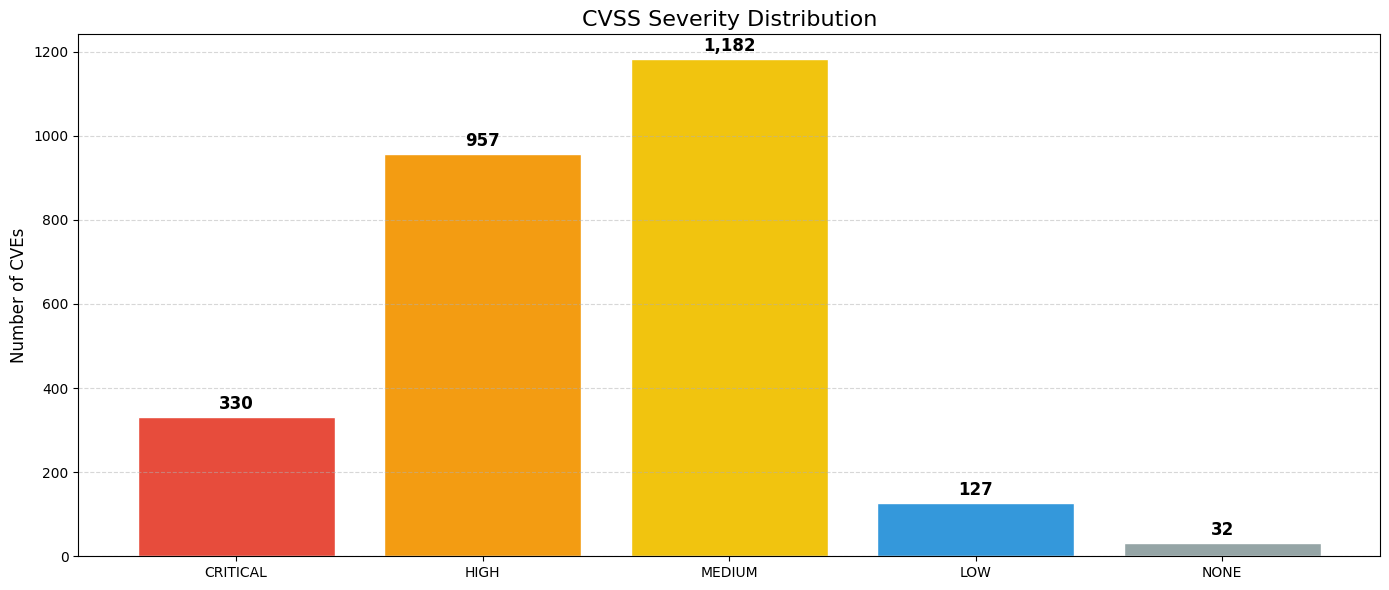

In [3]:
import matplotlib.pyplot as plt

SEVERITY_COLORS = {
    "CRITICAL": "#e74c3c",
    "HIGH": "#f39c12",
    "MEDIUM": "#f1c40f",
    "LOW": "#3498db",
    "NONE": "#95a5a6",
}
ORDER = ["CRITICAL", "HIGH", "MEDIUM", "LOW", "NONE"]

counts = df["cvss_base_severity"].value_counts()
counts = counts.reindex([s for s in ORDER if s in counts.index])
colors = [SEVERITY_COLORS[s] for s in counts.index]

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="white")
for bar, val in zip(bars, counts.values): # noqa: B905
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
            f"{val:,}", ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_title("CVSS Severity Distribution", fontsize=16)
ax.set_ylabel("Number of CVEs", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()

## Critical Vulnerabilities

In [4]:
critical = (
    df[df["cvss_base_score"] >= 9.0]
    .sort_values("cvss_base_score", ascending=False)
    .head(10)
)
print(f"{len(df[df['cvss_base_score'] >= 9.0]):,} CVEs with CVSS >= 9.0\n")
critical[["cve_id", "cvss_base_score", "description"]]

330 CVEs with CVSS >= 9.0



,cve_id,cvss_base_score,description
1644,CVE-2025-59818,10.0,This vulnerability allows authenticated attack...
914,CVE-2026-24729,10.0,An unrestricted upload of file with dangerous ...
924,CVE-2026-1699,10.0,"In the Eclipse Theia Website repository, the G..."
1603,CVE-2026-1633,10.0,The Synectix LAN 232 TRIO 3-Port serial to eth...
435,CVE-2025-63689,10.0,Multiple SQL injection vulnerabilitites in ycf...
1584,CVE-2026-25150,10.0,Qwik is a performance focused javascript frame...
1466,CVE-2025-70841,10.0,Dokans Multi-Tenancy Based eCommerce Platform ...
2073,CVE-2026-25725,10.0,Claude Code is an agentic coding tool. Prior t...
1929,CVE-2025-68121,10.0,"During session resumption in crypto/tls, if th..."
1252,CVE-2026-25142,10.0,SandboxJS is a JavaScript sandboxing library. ...


## EPSS vs CVSS

In [ ]:
scored = df.dropna(subset=["cvss_base_score", "epss_probability"]).copy()
scored = scored[scored["epss_probability"] > 0]
scored["severity"] = scored["cvss_base_severity"].fillna("NONE")

fig, ax = plt.subplots(figsize=(14, 6))
for sev in ["LOW", "MEDIUM", "HIGH", "CRITICAL"]:
    mask = scored["severity"] == sev
    ax.scatter(
        scored.loc[mask, "cvss_base_score"],
        scored.loc[mask, "epss_probability"],
        c=SEVERITY_COLORS[sev], label=sev, alpha=0.5, s=15, edgecolors="none",
    )
ax.set_yscale("log")
ax.set_xlabel("CVSS Base Score", fontsize=12)
ax.set_ylabel("EPSS Probability (log)", fontsize=12)
ax.set_title("EPSS Exploitation Probability vs CVSS Score", fontsize=16)
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
ds.to_parquet("../data/quick_cache.parquet")
print(f"Saved {len(ds):,} CVEs to data/quick_cache.parquet")